<div align="center">

**Федеральное государственное бюджетное образовательное учреждение высшего образования**

# «ФИНАНСОВЫЙ УНИВЕРСИТЕТ ПРИ ПРАВИТЕЛЬСТВЕ РОССИЙСКОЙ ФЕДЕРАЦИИ»

**Кафедра искусственного интеллекта**


## Пояснительная записка к курсовому проекту

по дисциплине **"Машинное обучение"**

на тему:


# «Машинное обучение в задачах предсказания оттока клиентов»

<br>

**Выполнила:**  
студентка группы ПМ24-5  
Антонова Анастасия Анатольевна

<br>

**Научный руководитель:**  
Емельянова Наталия Юрьевна

<br><br><br>

**Москва 2026**

</div>

# **Выбор и описание набора данных, постановка задачи**

**Актуальность работы:**

Увеличение доходности компании неразрывно связано с удержанием существующей клиентской базы и повышением их лояльности. Но в условиях высокой конкуренции на рынке главной проблемой является отток клиентов, который влечет за собой существенные финансовые потери.


Во-первых, затраты на рекламу для привлечения новых клиентов значительно превышают расходы на удержание уже созданной клиентской базы. А во-вторых, новый клиент может быть менее заинтересованным и вскоре отказаться от услуг.

Таким образом, прогнозирование оттока клиентов дает возможность вовремя среагировать и предотвратить потерю клиента, сделав, например, специальное предложение, опираясь на уже имеющиеся данные о пользователе. Это сильно упрощает задачу удержания клиентов.


**Предметная область**

Объект исследования — телекоммуникационная компания, предоставляющая услуги связи. Предмет исследования — процесс оттока клиентов и методы его прогнозирования на основе имеющихся данных.

**Цель работы:**

Построить и оценить модель бинарной классификации, позволяющую прогнозировать вероятность оттока клиентов.

**Тип задачи:**

Бинарная классификация. Целевая переменная Churn value принимает 1, если клиент ушел,и 0, если остался.

**Описание данных**

Работа выполнена на основе данных о телекоммуникационной компании. Датасет взят из открытого источника - платформа Kaggle. Использован набор данных "Telco customer churn: IBM dataset" весом 1.37MB, состоящий из информации о более чем 7000 пользователях, их географическом положении, демографических признаках, подключенных услугах, методах и сумме оплаты.

**Практическая значимость:**

Своевременное предсказание ухода клиента позволяет снизить отток с помощью различных выгодных для клиента предложений, оптимизировать маркетинговые расходы, за счёт чего увеличить прибыль, и автоматизировать процесс удержания клиентов.

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import time
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from imblearn.over_sampling import SMOTE
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

In [ ]:
df = pd.read_excel('Telco_customer_churn.xlsx')
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


# **Предварительный анализ и очистка данных**

CustomerID: Уникальный идентификатор, который идентифицирует каждого клиента.

Count: Значение, используемое в отчётности/дашбордах для подсчёта количества клиентов в отфильтрованном наборе.

Country: Страна основного места жительства клиента.

State: Штат основного места жительства клиента.

City: Город основного места жительства клиента.

Zip Code: Почтовый индекс основного места жительства клиента.

Lat Long: Объединённые широта и долгота основного места жительства клиента.

Latitude: Широта основного места жительства клиента.

Longitude: Долгота основного места жительства клиента.

Gender: Пол клиента: Мужской, Женский.

Senior Citizen: Указывает, является ли клиент пенсионером (65 лет и старше).

Partne: Указывает, есть ли у клиента партнёр.

Dependents: Указывает, проживает ли клиент с иждивенцами. Иждивенцами могут быть дети, родители, бабушки, дедушки и т.д.

Tenure Months: Указывает общее количество месяцев, которое клиент пользуется услугами компании на конец указанного квартала.

Phone Service: Указывает, подключён ли у клиента домашний телефонный сервис.

Multiple Lines: Указывает, подключены ли у клиента несколько телефонных линий.

Internet Service: Указывает, подключён ли у клиента интернет-сервис.

Online Security: Указывает, подключена ли дополнительная услуга онлайн-безопасности.

Online Backup: Указывает, подключена ли дополнительная услуга онлайн-резервного копирования.

Device Protection: Указывает, подключён ли дополнительный план защиты оборудования.

Tech Support: Указывает, подключён ли дополнительный план технической поддержки с сокращённым временем ожидания.

Streaming TV: Указывает, использует ли клиент интернет для просмотра телепередач от стороннего провайдера.

Streaming Movies: Указывает, использует ли клиент интернет для просмотра фильмов от стороннего провайдера.

Contract: Указывает текущий тип контракта.

Paperless Billing: Указывает, выбрал ли клиент безбумажные счета.

Payment Method: Указывает, как клиент оплачивает счёт.

Monthly Charges: Указывает текущую общую ежемесячную плату клиента за все услуги компании.

Total Charges: Указывает общую сумму платежей клиента, рассчитанную на конец указанного квартала.

Churn Label: Да - клиент ушёл из компании в этом квартале. Нет - клиент остался с компанией. Напрямую связан с Churn Value.

Churn Value: 1 - клиент ушёл из компании в этом квартале. 0 - клиент остался с компанией. Напрямую связан с Churn Label.

Churn Score: Значение от 0 до 100, рассчитанное с помощью прогностического инструмента IBM SPSS Modeler. Модель учитывает множество факторов, известных как причины оттока. Чем выше значение, тем выше вероятность, что клиент уйдёт.

CLTV: Пожизненная ценность клиента. Прогнозируемая CLTV рассчитывается с использованием корпоративных формул и существующих данных. Чем выше значение, тем ценнее клиент. Клиенты с высокой ценностью должны отслеживаться на предмет оттока.

Churn Reason: Конкретная причина ухода клиента из компании.

In [ ]:
print('Количество строк:' ,df.shape[0])
print('Количество столбцов:', df.shape[1])

Количество строк: 7043
Количество столбцов: 33


In [ ]:
print(df.info())
print(df.dtypes.value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   object 
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   object 
 3   State              7043 non-null   object 
 4   City               7043 non-null   object 
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   object 
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   object 
 10  Senior Citizen     7043 non-null   object 
 11  Partner            7043 non-null   object 
 12  Dependents         7043 non-null   object 
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   object 
 15  Multiple Lines     7043 non-null   object 
 16  Internet Service   7043 

Большинство признаков (73%) являются категориальными, потребуется их преобразование.

In [ ]:
print(df.isnull().sum())

CustomerID              0
Count                   0
Country                 0
State                   0
City                    0
Zip Code                0
Lat Long                0
Latitude                0
Longitude               0
Gender                  0
Senior Citizen          0
Partner                 0
Dependents              0
Tenure Months           0
Phone Service           0
Multiple Lines          0
Internet Service        0
Online Security         0
Online Backup           0
Device Protection       0
Tech Support            0
Streaming TV            0
Streaming Movies        0
Contract                0
Paperless Billing       0
Payment Method          0
Monthly Charges         0
Total Charges           0
Churn Label             0
Churn Value             0
Churn Score             0
CLTV                    0
Churn Reason         5174
dtype: int64


Пропуски есть только в Churn Reason, но это объясняется тем, что там содержится информация только о тех клиентах, которые ушли.

# **Разведочный анализ данных (EDA)**

In [ ]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [ ]:
df.describe(include=[object])

,CustomerID,Country,State,City,Lat Long,Gender,Senior Citizen,Partner,Dependents,Phone Service,...,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Total Charges,Churn Label,Churn Reason
count,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043,7043,7043.0,7043,1869
unique,7043,1,1,1129,1652,2,2,2,2,2,...,3,3,3,3,3,2,4,6531.0,2,20
top,3186-AJIEK,United States,California,Los Angeles,"34.159534, -116.425984",Male,No,No,No,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,20.2,No,Attitude of support person
freq,1,7043,7043,305,5,3555,5901,3641,5416,6361,...,3095,3473,2810,2785,3875,4171,2365,11.0,5174,192


Total charges показывает общую сумму платежей, поэтому его необходимо преобразовать в числовой вид.

Такие признаки как count, zip code, latitude, longitude не являются информативными, а churn score это результат работы другой модели, ее тоже не будем учитывать.

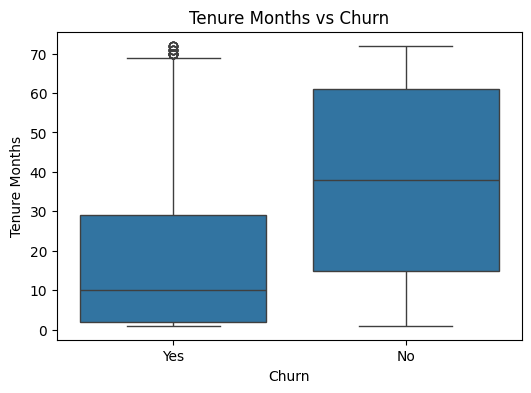

Чем дольше клиент пользуется услугами компании, тем реже он уходит. Новые клиенты наиболее подвержены оттоку.



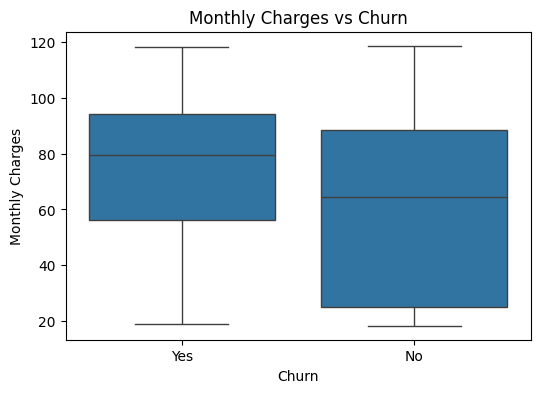

Чем выше ежемесячный платёж, тем выше риск оттока. Клиенты с низкими и средними платежами уходят реже.



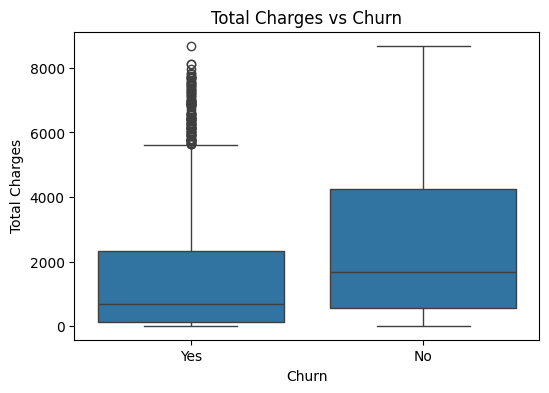

Низкая общая сумма платежей характерна для новых клиентов, которые чаще уходят. Высокая общая сумма указывает на давних клиентов.



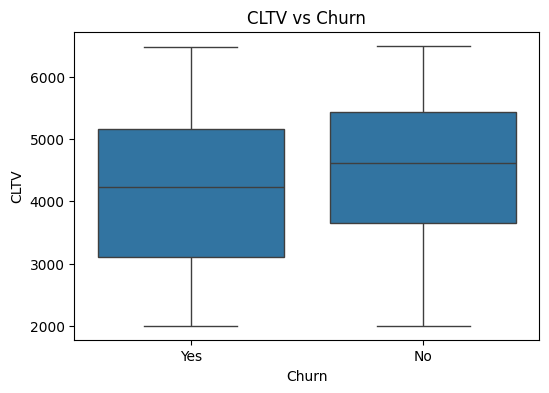

CLTV не показывает сильной связи с оттоком. Клиенты с разной пожизненной ценностью уходят примерно одинаково.



In [ ]:
df['Total Charges'] = pd.to_numeric(df['Total Charges'],  errors='coerce')
df = df.dropna(subset=['Total Charges'])

numeric_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']
numeric_comments = {
    'Tenure Months': "Чем дольше клиент пользуется услугами компании, тем реже он уходит. Новые клиенты наиболее подвержены оттоку.",
    'Monthly Charges': "Чем выше ежемесячный платёж, тем выше риск оттока. Клиенты с низкими и средними платежами уходят реже.",
    'Total Charges': "Низкая общая сумма платежей характерна для новых клиентов, которые чаще уходят. Высокая общая сумма указывает на давних клиентов.",
    'CLTV': "CLTV не показывает сильной связи с оттоком. Клиенты с разной пожизненной ценностью уходят примерно одинаково."
}

for col in numeric_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x='Churn Label', y=col, data=df)
    plt.title(f"{col} vs Churn")
    plt.xlabel("Churn")
    plt.ylabel(col)
    plt.show()

    print(f"{numeric_comments[col]}\n")

Выбросы:

Tenure Months - несколько клиентов с большим стажем (70+ месяцев) всё же ушли. Это редкие исключения, аномалии на фоне общей закономерности, что давние клиенты редко уходят.

Total Charges - несмотря на то, что давние клиенты редко уходят, существуют исключения — клиенты с накопленными платежами (6000-8000+), которые расторгли договор.

Очищать данные от выбросов нет необходимости, так как они информативны.

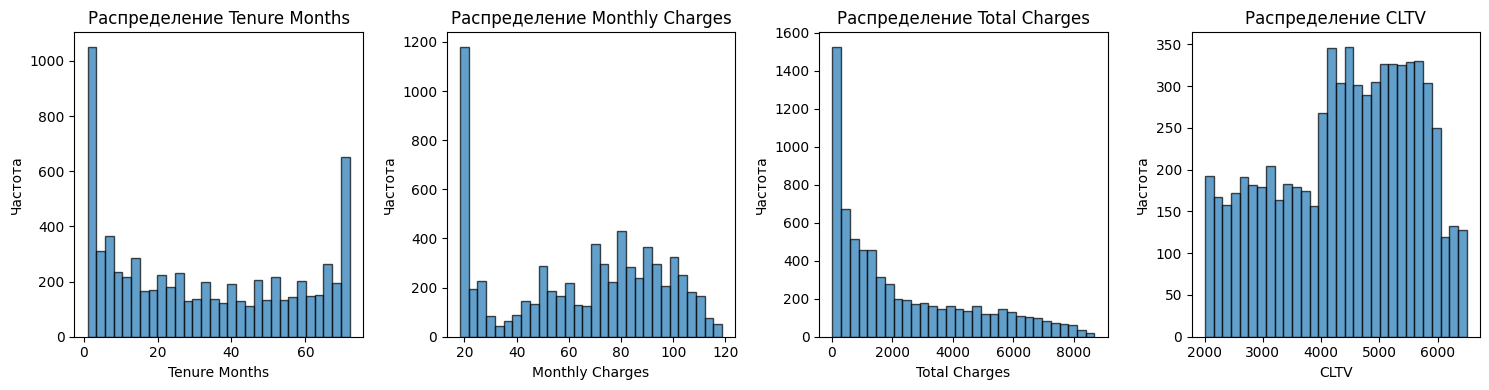

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))

for i, col in enumerate(numeric_cols):
    axes[i].hist(df[col], bins=30, edgecolor='black', alpha=0.7)
    axes[i].set_title(f'Распределение {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Частота')
plt.tight_layout()
plt.show()

Опираясь на графики, можно сделать вывод, что распределение признаков не является нормальным, потребуется стандартизация.

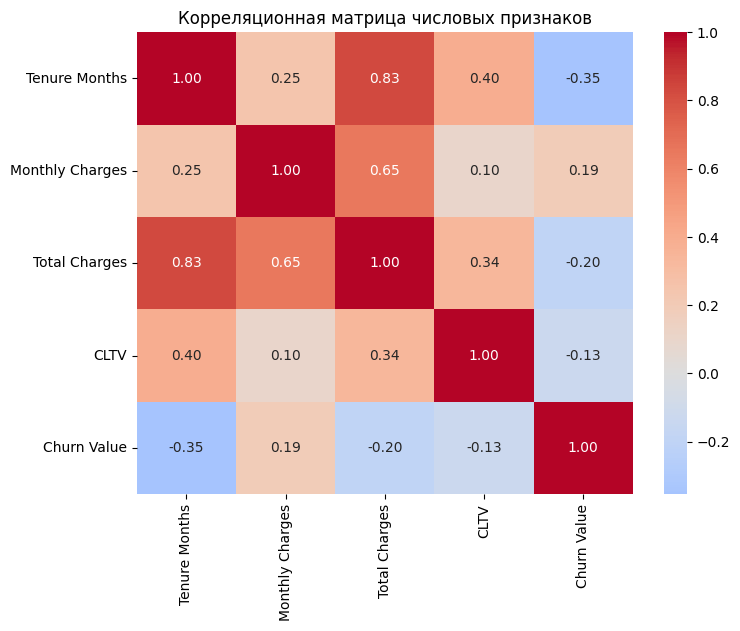

Корреляция признаков с Churn Value:
Churn Value        1.000000
Monthly Charges    0.192858
CLTV              -0.128253
Total Charges     -0.199484
Tenure Months     -0.354049
Name: Churn Value, dtype: float64


In [ ]:
numeric_cols = ['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV', 'Churn Value']
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Корреляционная матрица числовых признаков')
plt.show()

print("Корреляция признаков с Churn Value:")
print(corr_matrix['Churn Value'].sort_values(ascending=False))

Наибольшее влияние на отток оказывает Tenure Months (r = -0.35): чем дольше клиент пользуется услугами, тем реже он уходит. Monthly Charges (r = 0.19) имеет слабую положительную связь: более высокие платежи незначительно повышают риск оттока. Total Charges и CLTV демонстрируют очень слабую корреляцию.

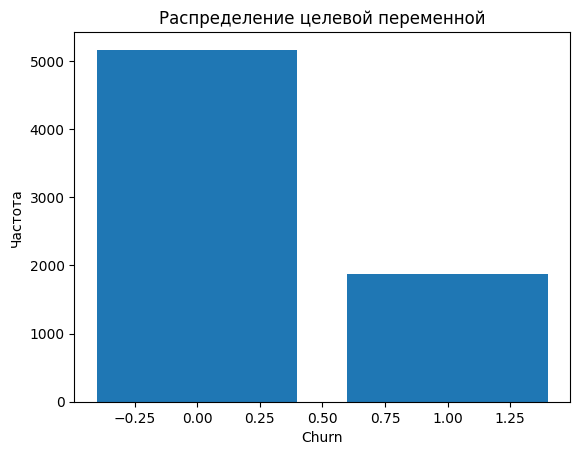

In [ ]:
counts = df['Churn Value'].value_counts()

plt.bar(counts.index, counts.values)
plt.xlabel('Churn')
plt.ylabel('Частота')
plt.title('Распределение целевой переменной')
plt.show()

Целевая переменная имеет значительный дисбаланс. Для корректного обучения меделей потребуется использование стратификации при разделении данных на обучающую и тестовую выборки, а также при кросс-валидации.

In [ ]:
drop_info = []

n_unique = df['CustomerID'].nunique()
n_total = len(df['CustomerID'])
if n_unique == n_total:
    drop_info.append(('CustomerID', f'Уникальный идентификатор ({n_unique} из {n_total})'))

if df['Count'].nunique() == 1:
    drop_info.append(('Count', f'Константный признак (все значения = {df["Count"].iloc[0]})'))

if df['Country'].nunique() == 1:
    drop_info.append(('Country', f'Нет вариативности (все = {df["Country"].iloc[0]})'))

if df['State'].nunique() == 1:
    drop_info.append(('State', f'Нет вариативности (все = {df["State"].iloc[0]})'))

n_unique_city = df['City'].nunique()
if n_unique_city > 500:
    drop_info.append(('City', f'Слишком высокая кардинальность ({n_unique_city} уникальных городов)'))

n_unique_zip = df['Zip Code'].nunique()
if n_unique_zip > 500:
    drop_info.append(('Zip Code', f'Слишком высокая кардинальность ({n_unique_zip} уникальных индексов)'))

drop_info.append(('Lat Long', 'Дублирует признаки Latitude и Longitude'))

if df['Latitude'].std() < 0.1:
    drop_info.append(('Latitude', f'Низкая вариативность (std = {df["Latitude"].std():.4f})'))

if df['Longitude'].std() < 0.1:
    drop_info.append(('Longitude', f'Низкая вариативность (std = {df["Longitude"].std():.4f})'))

churn_label_values = df['Churn Label'].map({'Yes': 1, 'No': 0})
if (churn_label_values == df['Churn Value']).all():
    drop_info.append(('Churn Label', 'Полностью дублирует Churn Value (Yes/No = 1/0)'))

null_percent = df['Churn Reason'].isnull().sum()
if null_percent > 50:
    drop_info.append(('Churn Reason', f'Большое количество пропусков ({null_percent} из 7043)'))

drop_info.append(('Latitude', 'Отсутствует причино-следственная связь с оттоком клиентов'))
drop_info.append(('Longitude', 'Отсутствует причино-следственная связь с оттоком клиентов'))
drop_info.append(('Total Charges', 'Высокая корреляция с Tenure Months(r=0.83) - мультиколлинеарность'))
drop_info.append(('CLTV', 'Очень слабая корреляция с целевой переменной(r = -0.13) - низкая предсказательная сила'))
drop_info.append(('Churn Score', 'Признак является результатом предсказания другой модели'))

print("\n{:<20} {:<50}".format("Признак", "Причина удаления"))
print("-" * 70)
for col, reason in drop_info:
    print("{:<20} | {:<50}".format(col, reason))

print(f"\nИтого: {len(drop_info)} признаков")


Признак              Причина удаления                                  
----------------------------------------------------------------------
CustomerID           | Уникальный идентификатор (7032 из 7032)           
Count                | Константный признак (все значения = 1)            
Country              | Нет вариативности (все = United States)           
State                | Нет вариативности (все = California)              
City                 | Слишком высокая кардинальность (1129 уникальных городов)
Zip Code             | Слишком высокая кардинальность (1652 уникальных индексов)
Lat Long             | Дублирует признаки Latitude и Longitude           
Churn Label          | Полностью дублирует Churn Value (Yes/No = 1/0)    
Churn Reason         | Большое количество пропусков (5163 из 7043)       
Latitude             | Отсутствует причино-следственная связь с оттоком клиентов
Longitude            | Отсутствует причино-следственная связь с оттоком клиентов
Total Charges  

In [ ]:
drop_cols =[item[0] for item in drop_info]
df_ = df.drop(columns=drop_cols)

print(f"\nРазмер исходного датасета: {df.shape[1]} признаков")
print(f"Размер после удаления: {df_.shape[1]} признаков")
print(f"Удалено: {len(drop_cols)} признаков")
print(df_.dtypes.value_counts())
df_.head()


Размер исходного датасета: 33 признаков
Размер после удаления: 19 признаков
Удалено: 14 признаков
object     16
int64       2
float64     1
Name: count, dtype: int64


,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Churn Value
0,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,1
1,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,1
2,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,1
3,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,1
4,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,1


В наборе данных присутствуют 16 категориальных признаков, которые требуют преобразования в числовой формат.

# **Преобразование признаков (feature engineering)**

In [ ]:
categorical_cols = ['Gender', 'Senior Citizen', 'Partner', 'Dependents',
                    'Phone Service', 'Paperless Billing', 'Multiple Lines',
                    'Online Security', 'Online Backup', 'Device Protection',
                    'Tech Support', 'Streaming TV', 'Streaming Movies',
                    'Internet Service', 'Payment Method']

df_encoded = pd.get_dummies(df_, columns=categorical_cols, drop_first=True)


contract_order = {'Month-to-month': 0, 'One year': 1, 'Two year': 2}
df_encoded['Contract'] = df_['Contract'].map(contract_order)

Все категориальные признаки, кроме Contract, преобразованы с помощью One-Hot Encoding, так как не имеют естественного порядка. Параметр drop_first=True использован для избежания мультиколлинеарности.

Признак Contract преобразован через Label Encoding, так как имеет естественный порядок.

In [ ]:
service_cols = ['Online Security_Yes', 'Online Backup_Yes', 'Device Protection_Yes', 'Tech Support_Yes']
df_encoded['Total Extra Services'] = df_encoded[service_cols].sum(axis=1)

streaming_cols = ['Streaming TV_Yes', 'Streaming Movies_Yes']
df_encoded['Total Streaming'] = df_encoded[streaming_cols].sum(axis=1)

df_encoded.head()

,Tenure Months,Contract,Monthly Charges,Churn Value,Gender_Male,Senior Citizen_Yes,Partner_Yes,Dependents_Yes,Phone Service_Yes,Paperless Billing_Yes,...,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Internet Service_Fiber optic,Internet Service_No,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check,Total Extra Services,Total Streaming
0,2,0,53.85,1,True,False,False,False,True,True,...,False,False,False,False,False,False,False,True,2,0
1,2,0,70.70,1,False,False,False,True,True,True,...,False,False,False,True,False,False,True,False,0,0
2,8,0,99.65,1,False,False,False,True,True,True,...,True,False,True,True,False,False,True,False,1,2
3,28,0,104.80,1,False,False,True,True,True,True,...,True,False,True,True,False,False,True,False,2,2
4,49,0,103.70,1,True,False,False,True,True,True,...,True,False,True,True,False,False,False,False,2,2


Признак Total Extra Services подсчитывает общее количество оказываемых дополнительных услуг. Чем больше услуг - тем меньше риск оттока клиентов.

Признак Total Streaming суммирует наличие стриминговых услуг. Чем их больше - тем выше вовлеченость клиента.

# **Разделение данных на обучающую и тестовую выборки**

In [ ]:
X = df_encoded.drop(columns=['Churn Value'])
y = df_encoded['Churn Value']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

- Соотношение 80/20 — стандартный компромисс между объёмом обучения (достаточно для выявления закономерностей) и тестирования (достаточно для стабильной оценки).
- Стратификация — необходима из-за дисбаланса классов, сохраняет пропорцию целевой переменной в обеих выборках.

# **Обучение нескольких моделей**

Распределения признаков не являются нормальными,поэтому выполним стандартизацию.

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

Для решения задачи используем 7 моделей, представляющих различные подходы к классификации:

1. Логистическая регрессия — базовая линейная модель, позволяющая оценить вклад признаков.
2. Дерево решений — простой интерпретируемый алгоритм для выявления нелинейных зависимостей.
3. Случайный лес — ансамбль деревьев для повышения устойчивости и качества.
4. Градиентный бустинг — мощный ансамблевый метод, часто дающий лучшее качество.
5. SVM — метод опорных векторов для поиска оптимальной разделяющей гиперплоскости.
6. k-NN — простой непараметрический алгоритм как baseline для сравнения.
7. XGBoost — оптимизированная реализация градиентного бустинга.

In [ ]:
models = {
    '1. Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    '2. Decision Tree': DecisionTreeClassifier(max_depth=10, random_state=42),
    '3. Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    '4. Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    '5. SVM': SVC(kernel='rbf', probability=True, random_state=42),
    '6. k-NN': KNeighborsClassifier(n_neighbors=5),
    '7. XGBoost': XGBClassifier(n_estimators=100, random_state=42, eval_metric='logloss')
    }

results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    print(f"\n{name}")

    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='roc_auc')

    start_time = time.time()
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]

    train_time = time.time() - start_time

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_pred_proba)

    results.append({
        'Model': name,
        'Train Time (s)': round(train_time, 3),
        'CV ROC-AUC Mean': round(cv_scores.mean(), 4),
        'CV ROC-AUC Std': round(cv_scores.std(), 4),
        'Accuracy': round(accuracy, 4),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1': round(f1, 4),
        'ROC-AUC': round(roc_auc, 4)
    })

    print(f"Время обучения: {train_time:.3f} сек")
    print(f"CV ROC-AUC: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1: {f1:.4f}")
    print(f"ROC-AUC: {roc_auc:.4f}")


1. Logistic Regression
Время обучения: 0.341 сек
CV ROC-AUC: 0.8585 (+/- 0.0085)
Accuracy: 0.8045
Precision: 0.6427
Recall: 0.5963
F1: 0.6186
ROC-AUC: 0.8419

2. Decision Tree
Время обучения: 0.027 сек
CV ROC-AUC: 0.7688 (+/- 0.0192)
Accuracy: 0.7662
Precision: 0.5728
Recall: 0.4733
F1: 0.5183
ROC-AUC: 0.7566

3. Random Forest
Время обучения: 0.748 сек
CV ROC-AUC: 0.8358 (+/- 0.0095)
Accuracy: 0.7854
Precision: 0.6161
Recall: 0.5107
F1: 0.5585
ROC-AUC: 0.8226

4. Gradient Boosting
Время обучения: 0.951 сек
CV ROC-AUC: 0.8643 (+/- 0.0059)
Accuracy: 0.7996
Precision: 0.6411
Recall: 0.5588
F1: 0.5971
ROC-AUC: 0.8494

5. SVM
Время обучения: 7.777 сек
CV ROC-AUC: 0.7981 (+/- 0.0091)
Accuracy: 0.7818
Precision: 0.6450
Recall: 0.3984
F1: 0.4926
ROC-AUC: 0.7998

6. k-NN
Время обучения: 0.193 сек
CV ROC-AUC: 0.7828 (+/- 0.0092)
Accuracy: 0.7655
Precision: 0.5618
Recall: 0.5348
F1: 0.5479
ROC-AUC: 0.7882

7. XGBoost
Время обучения: 0.147 сек
CV ROC-AUC: 0.8413 (+/- 0.0072)
Accuracy: 0.7726
Prec

In [ ]:
results_df = pd.DataFrame(results)
results_df = results_df.sort_values('ROC-AUC', ascending=False)
print(results_df.to_string(index=False))

                 Model  Train Time (s)  CV ROC-AUC Mean  CV ROC-AUC Std  Accuracy  Precision  Recall     F1  ROC-AUC
  4. Gradient Boosting           0.951           0.8643          0.0059    0.7996     0.6411  0.5588 0.5971   0.8494
1. Logistic Regression           0.341           0.8585          0.0085    0.8045     0.6427  0.5963 0.6186   0.8419
            7. XGBoost           0.147           0.8413          0.0072    0.7726     0.5750  0.5535 0.5640   0.8266
      3. Random Forest           0.748           0.8358          0.0095    0.7854     0.6161  0.5107 0.5585   0.8226
                5. SVM           7.777           0.7981          0.0091    0.7818     0.6450  0.3984 0.4926   0.7998
               6. k-NN           0.193           0.7828          0.0092    0.7655     0.5618  0.5348 0.5479   0.7882
      2. Decision Tree           0.027           0.7688          0.0192    0.7662     0.5728  0.4733 0.5183   0.7566


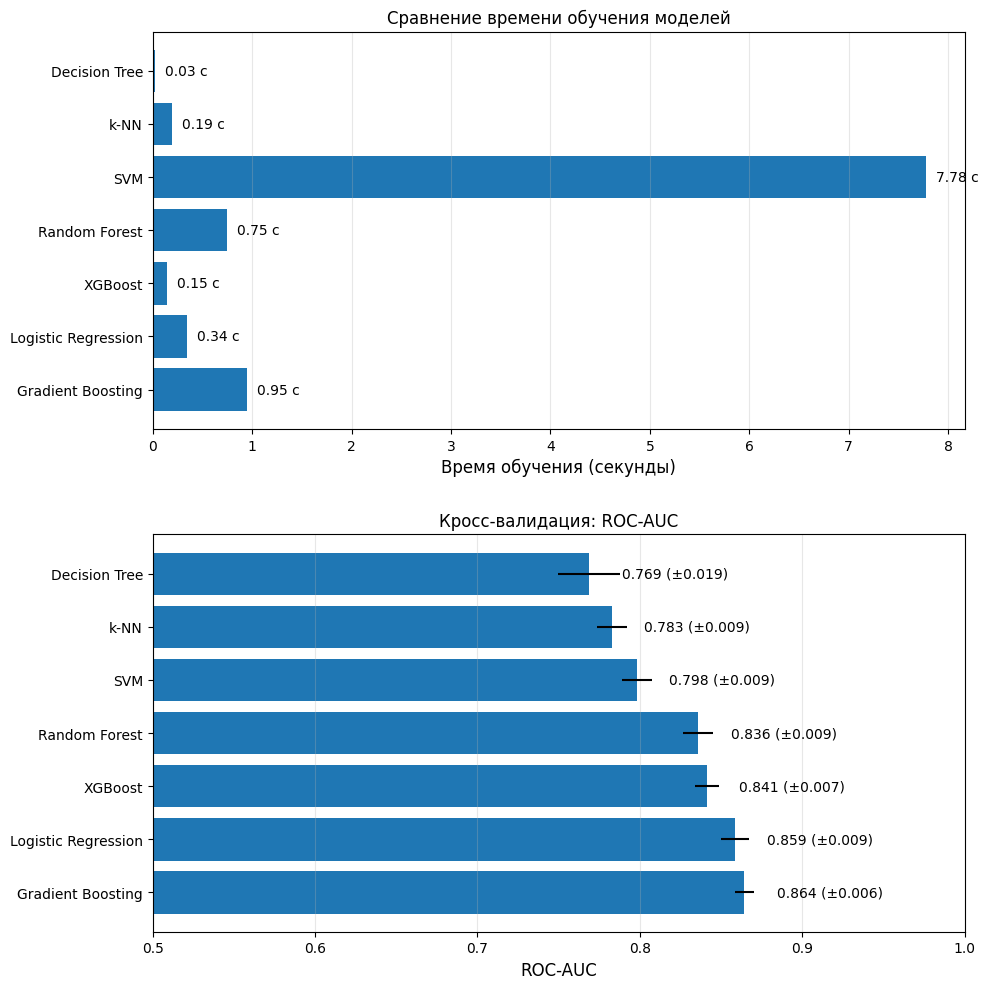

In [ ]:
models_names = results_df['Model'].str.replace(r'^\d+\.\s', '', regex=True)

fig, axes = plt.subplots(2, 1, figsize=(10, 10))

ax1 = axes[0]
bars1 = ax1.barh(models_names, results_df['Train Time (s)'])
ax1.set_xlabel('Время обучения (секунды)', fontsize=12)
ax1.set_title('Сравнение времени обучения моделей')
ax1.grid(True, alpha=0.3, axis='x')

for bar, val in zip(bars1, results_df['Train Time (s)']):
    ax1.text(val + 0.1, bar.get_y() + bar.get_height()/2, f'{val:.2f} с', va='center')

ax2 = axes[1]
bars2 = ax2.barh(models_names, results_df['CV ROC-AUC Mean'], xerr=results_df['CV ROC-AUC Std'])

ax2.set_xlabel('ROC-AUC', fontsize=12)
ax2.set_title('\nКросс-валидация: ROC-AUC')
ax2.set_xlim(0.5, 1.0)
ax2.grid(True, alpha=0.3, axis='x')

for bar, val, std in zip(bars2, results_df['CV ROC-AUC Mean'], results_df['CV ROC-AUC Std']):
    ax2.text(val + 0.02, bar.get_y() + bar.get_height()/2, f'{val:.3f} (±{std:.3f})', va='center')

plt.tight_layout()
plt.show()

Несмотря на то, что Gradient Boosting показывает немного более высокий ROC-AUC, логистическая регрессия превосходит его по приоритетной метрике Recall, а также по F1-мере и времени обучения. Таким образом, логистическая регрессия является наиболее оптимальной моделью для решения задачи, однако для окончательного выбора необходимо также проанализировать кривые обучения и матрицы ошибок.

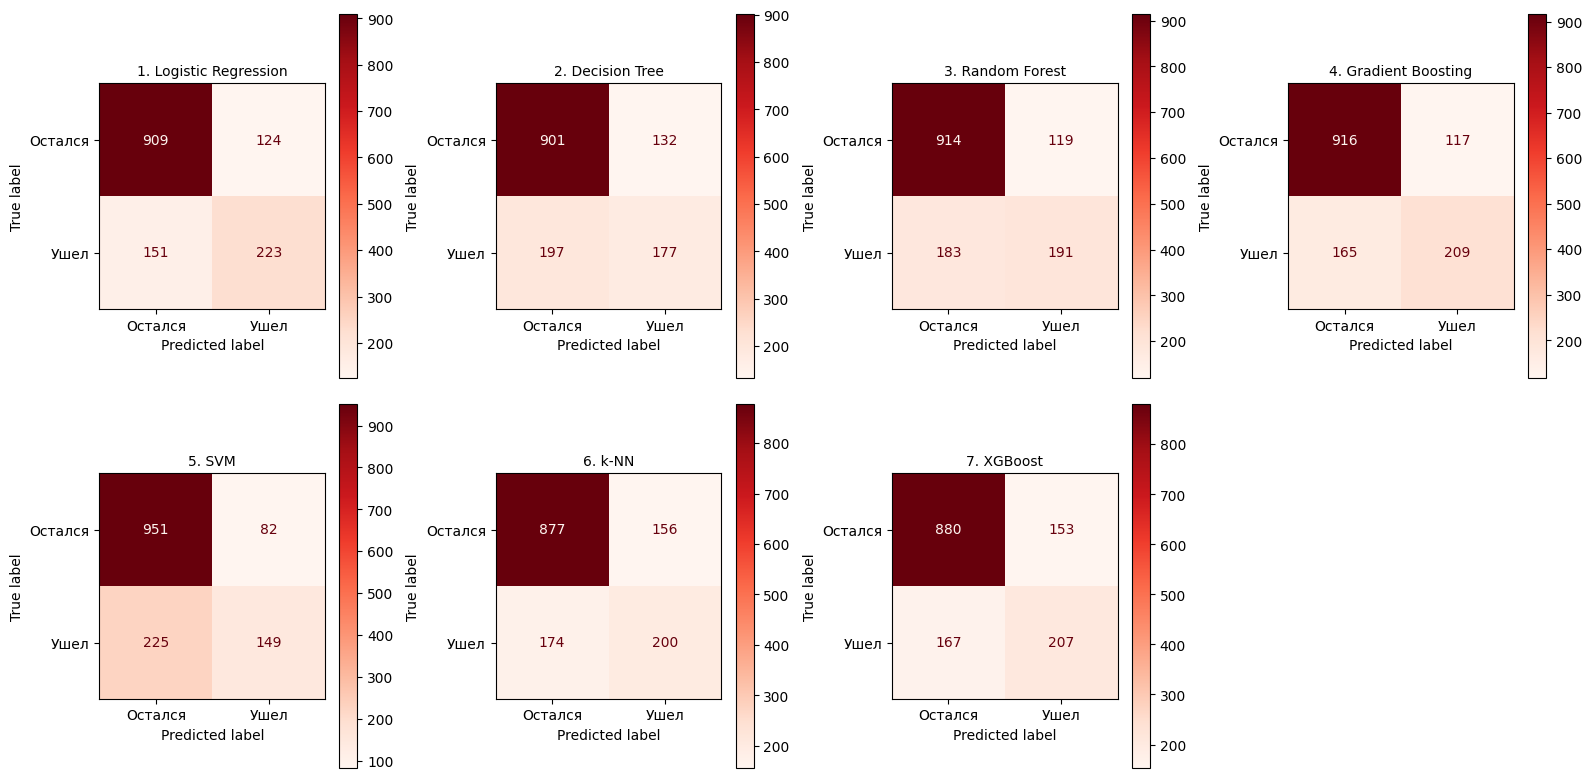

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.flatten()
axes[-1].axis('off')

for idx, (name, model) in enumerate(models.items()):
    y_pred = model.predict(X_test)
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, ax=axes[idx], cmap='Reds',
        display_labels=['Остался', 'Ушел'])
    axes[idx].set_title(name, fontsize=10)

plt.tight_layout()
plt.show()

Логистическая регрессия верно классифицировала 911 клиентов как "оставшихся" и 223 как "ушедших", пропустив 122 ушедших клиента (False Negatives) и ошибочно предсказав отток 151 клиенту.

У Gradient Boosting результат по нахождению ушедших клиентов лучше (209 против 223), но при этом модель пропустила 117.

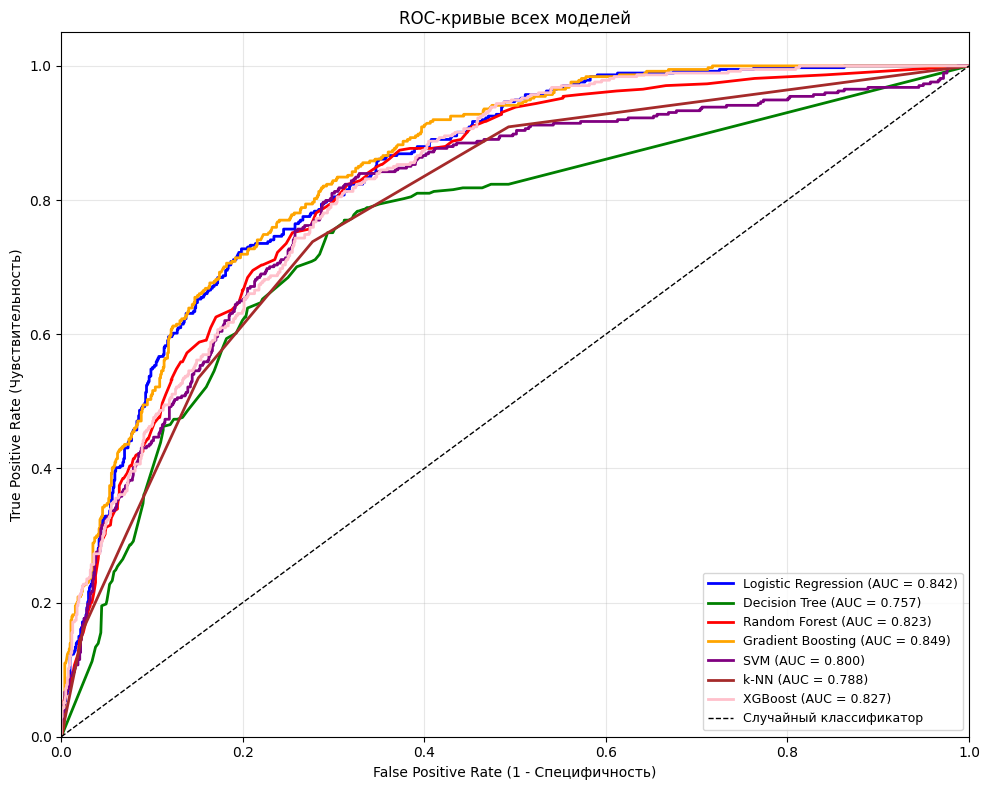

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score
plt.figure(figsize=(10, 8))

colors = ['blue', 'green', 'red', 'orange', 'purple', 'brown', 'pink']

for (name, model), color in zip(models.items(), colors):
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    auc = roc_auc_score(y_test, y_pred_proba)
    short_name = name.split('. ', 1)[-1]
    plt.plot(fpr, tpr, color=color, lw=2, label=f'{short_name} (AUC = {auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Случайный классификатор')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Специфичность)')
plt.ylabel('True Positive Rate (Чувствительность)')
plt.title('ROC-кривые всех моделей')
plt.legend(loc='lower right', fontsize=9)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Gradient Boosting демонстрирует наилучшую ROC-кривую, наиболее близкую к верхнему левому углу (AUC = 0.849), это подтверждает его лидерство по общей разделяющей способности. Логистическая регрессия (AUC = 0.842) и XGBoost (0.827) также показывают хорошие результаты.

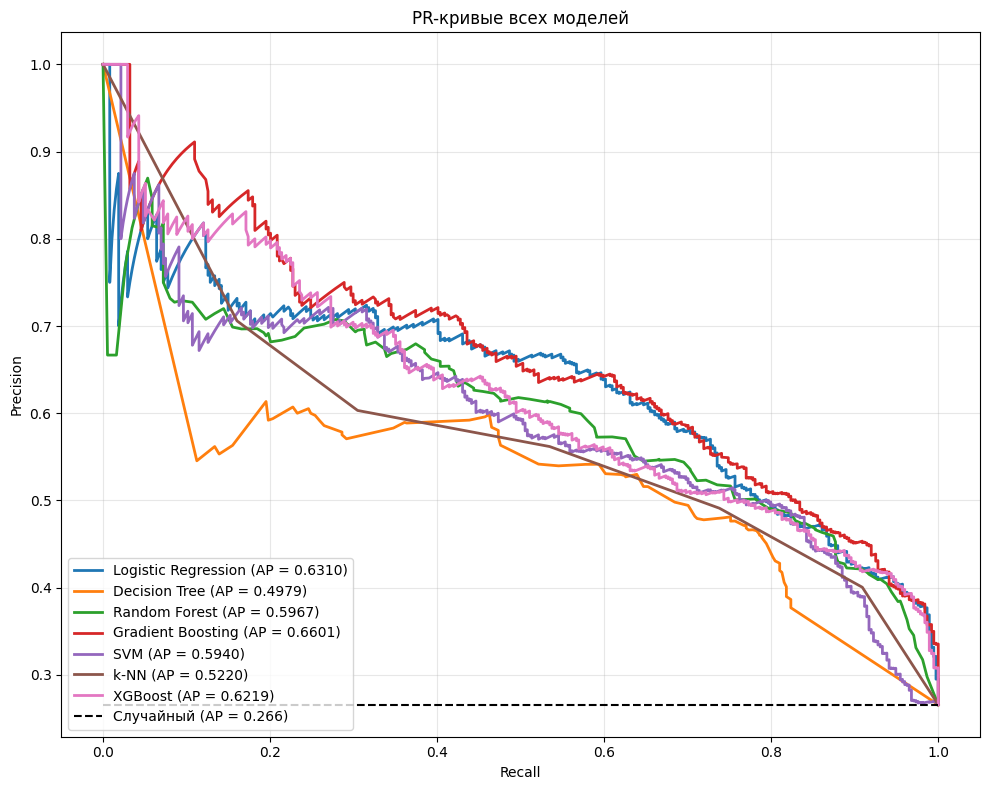

In [ ]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 8))

for name, model in models.items():
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    ap = average_precision_score(y_test, y_pred_proba)
    precision, recall, _ = precision_recall_curve(y_test, y_pred_proba)
    short_name = name.split('. ', 1)[-1]
    plt.plot(recall, precision, lw=2, label=f'{short_name} (AP = {ap:.4f})')

plt.plot([0, 1], [y_test.mean(), y_test.mean()], 'k--', label=f'Случайный (AP = {y_test.mean():.3f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('PR-кривые всех моделей')
plt.legend(loc='lower left')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Gradient Boosting показывает лучший Average Precision = 0.66 - наилучшее качество предсказания уходящих клиентов. Логистическая регрессия - 0.631 и XGBoost - 0.622 также демонстрируют хорошие результаты. Все модели значительно превосходят случайный классификатор - 0.266, что подтверждает их практическую ценность.

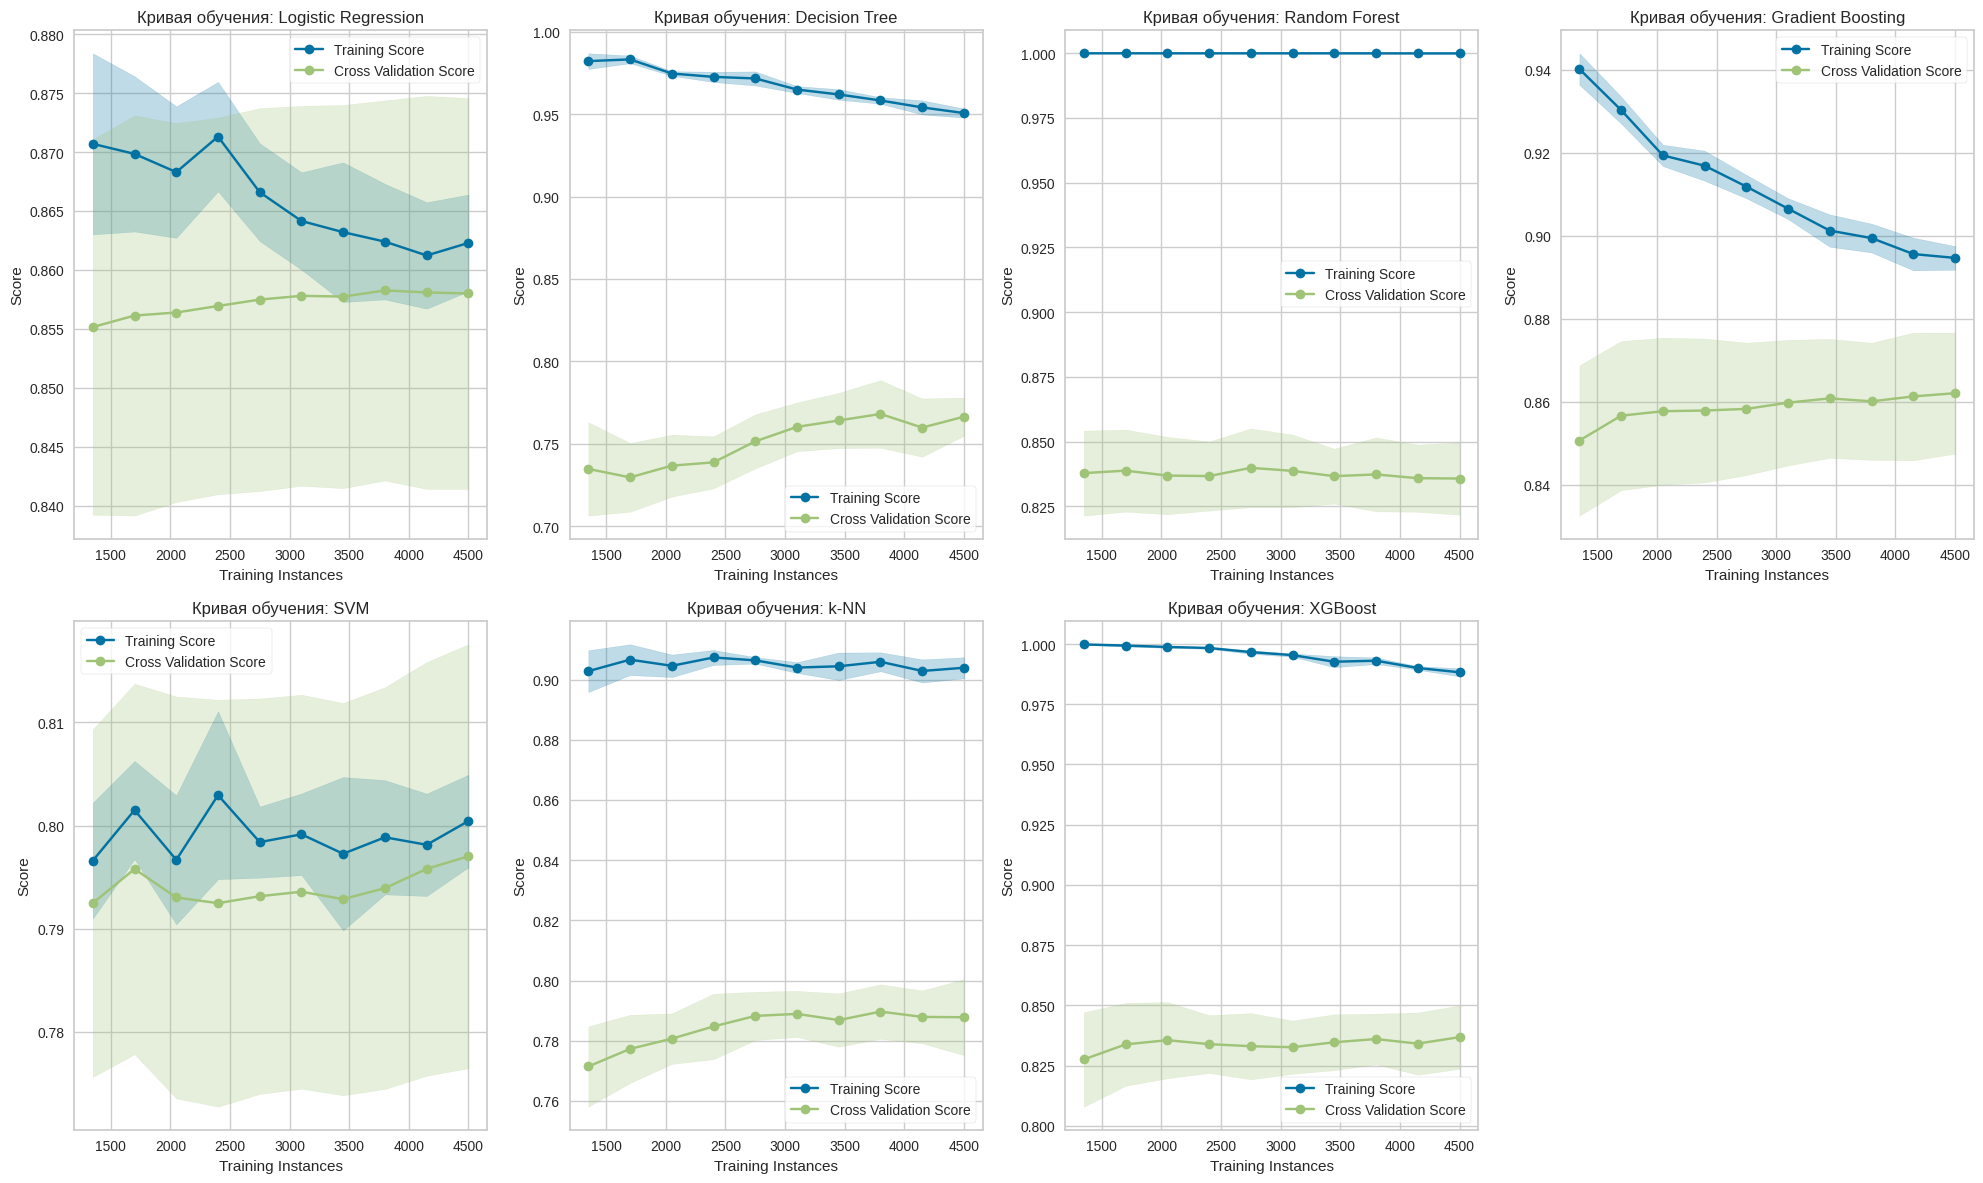

In [ ]:
from yellowbrick.model_selection import LearningCurve
fig, axes = plt.subplots(2, 4, figsize=(20, 12))
axes = axes.flatten()

for idx, (name, model) in enumerate(models.items()):
    short_name = name.split('. ', 1)[-1]
    visualizer = LearningCurve(
        model,
        train_sizes=np.linspace(0.3, 1.0, 10),
        cv=5,
        scoring='roc_auc',
        n_jobs=-1,
        ax=axes[idx],
        title=f'Кривая обучения: {short_name}'
    )

    visualizer.fit(X_train, y_train)
    visualizer.finalize()

axes[-1].axis('off')

plt.tight_layout()
plt.show()

Логистическая регрессия демонстрирует минимальный разрыв между обучающей и валидационной кривыми, что свидетельствует об отсутствии переобучения.

Gradient Boosting показывает небольшое переобучение.

**Вывод:**

Gradient Boosting показывает наилучшие показатели по ROC-AU и AP, но модель значительно уступает в скорости и имеет небольшое переобучение. Для данной бизнес-задач лучшим выбором является логистическая регрессия.

# **Выбор перспективной модели и настройка гиперпараметров**

Используем метод GridSearchCV для подбора гиперпараметров логистической регрессии, так как он обеспечивает полный перебор всех комбинаций параметров, использует кросс-валидацию для оценки стабильности и оптимизирует приоритетную метрику Recall.

In [ ]:
from sklearn.model_selection import GridSearchCV
lr = LogisticRegression(random_state=42, max_iter=1000)

param_grid = {
    'C': [0.001, 0.01, 0.1, 1, 10, 100],
    'penalty': ['l1', 'l2'],
    'solver': ['liblinear', 'saga'],
    'class_weight': [None, 'balanced']
}

grid_search = GridSearchCV(
    lr, param_grid,
    cv=5,
    scoring='recall',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)
print(f"Лучшие параметры: {grid_search.best_params_}")
print(f"Лучший Recall (CV): {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Лучшие параметры: {'C': 0.01, 'class_weight': 'balanced', 'penalty': 'l1', 'solver': 'liblinear'}
Лучший Recall (CV): 0.8281


GridSearchCV перебрал 48 комбинаций параметров с 5-кратной кросс-валидацией (всего 240 обучений). Итоговый лучший Recall на кросс-валидации составил 0.8281. Это означает, что модель в верно определяет около 83% потенциально уходящих клиентов.

C=0.01 указывает на сильную L1-регуляризацию, что позволяет избежать переобучения и лучше обучаться на новых данных. а параметра class_weight='balance' автоматически скорректировал веса классов.

In [ ]:
best_lr = grid_search.best_estimator_

y_pred = best_lr.predict(X_test)
y_pred_proba = best_lr.predict_proba(X_test)[:, 1]
from sklearn.metrics import recall_score, precision_score, f1_score, roc_auc_score, accuracy_score

print("Оценка модели на тестовой выборке")
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}")

print("\nСравнение:")
print(f"Recall на CV: 0.8281")
print(f"Recall на тесте: {recall_score(y_test, y_pred):.4f}")

Оценка модели на тестовой выборке
Accuracy:  0.7193
Precision: 0.4836
Recall:    0.8289
F1-score:  0.6108
ROC-AUC:   0.8357

Сравнение:
Recall на CV: 0.8281
Recall на тесте: 0.8289


 Модель демонстрирует стабильность и отсутствие переобучения: показатель Recall на тестовых данных (0.8289) практически совпал с лучшим результатом кросс-валидации (0.8281).

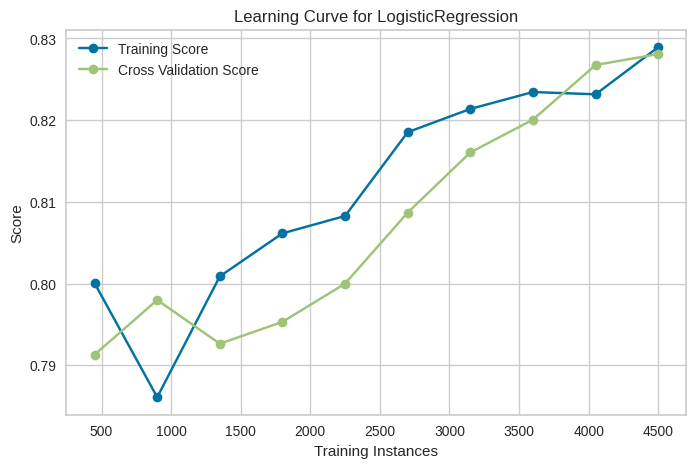

Разрыв Train-Val: 0.0008


In [ ]:
from sklearn.model_selection import learning_curve
train_sizes, train_scores, val_scores = learning_curve(
    best_lr, X_train, y_train,
    cv=5, scoring='recall',
    train_sizes=np.linspace(0.1, 1.0, 10)
)

train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
gap = train_mean[-1] - val_mean[-1]

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', label='Training Score')
plt.plot(train_sizes, val_mean, 'o-', label='Cross Validation Score')
plt.xlabel('Training Instances')
plt.ylabel('Score')
plt.title('Learning Curve for LogisticRegression')
plt.legend()
plt.grid(True)
plt.show()

print(f"Разрыв Train-Val: {gap:.4f}")

График демонстрирует практически полное совпадение тренировочной и валидационной кривых, которые сходятся к значению ~0.828. Разрыв между ними составляет всего 0.0008. Модель не переобучена, и одинаково хорошо работает как на обучающих, так и на новых данных.

# **Улучшение модели**

In [ ]:
feature_names = X_train.columns.tolist()

X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=feature_names)

experiments = {
    'Базовая модель': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'transform': None
    },
    'Взвешивание классов': {
        'model': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
        'transform': None
    },
    'SMOTE': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'transform': 'smote'
    },
    'SelectKBest': {
        'model': LogisticRegression(max_iter=1000, random_state=42),
        'transform': 'kbest'
    },
    'Лучшая модель (GridSearchCV)': {
        'model': grid_search.best_estimator_,
        'transform': None
    }
}

In [ ]:
res = []

for name, config in experiments.items():
    if config['transform'] == 'smote':
        smote = SMOTE(random_state=42)
        X_train_transformed, y_train_transformed = smote.fit_resample(X_train_scaled, y_train)
        X_test_transformed = X_test_scaled

    elif config['transform'] == 'kbest':
        selector = SelectKBest(score_func=f_classif, k=10)
        X_train_transformed = selector.fit_transform(X_train_scaled, y_train)
        X_test_transformed = selector.transform(X_test_scaled)
        y_train_transformed = y_train

    else:
        X_train_transformed = X_train_scaled
        X_test_transformed = X_test_scaled
        y_train_transformed = y_train

    model = config['model']
    model.fit(X_train_transformed, y_train_transformed)

    y_pred = model.predict(X_test_transformed)
    y_proba = model.predict_proba(X_test_transformed)[:, 1]

    res.append({
        'Метод': name,
        'Recall': recall_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'F1': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    })

res_df = pd.DataFrame(res)
res_df = res_df.sort_values('Recall', ascending=False)

print(res_df.to_string(index=False))

                       Метод   Recall  Precision       F1  ROC-AUC
Лучшая модель (GridSearchCV) 0.831551   0.473364 0.603298 0.839735
         Взвешивание классов 0.775401   0.501730 0.609244 0.841447
                       SMOTE 0.756684   0.508993 0.608602 0.840329
              Базовая модель 0.588235   0.637681 0.611961 0.841696
                 SelectKBest 0.564171   0.627976 0.594366 0.837037


Регуляризация + взвешивание классов дали максимальный эффект: Recall вырос с 0.588 (базовая) до 0.832 (лучшая модель) - ~ 42%

SMOTE оказался менее эффективным, чем взвешивание классов, для данной задачи(Recall - 0.756 против 0.775 при взешивание).

SelectKBest не улучшил, а ухудшил результаты.

Низкая Precision (0.473) — модель готова ошибиться, лишь бы не пропустить уходящего клиента.

# **Эксперименты с порядком предобработки и понижением размерности**

In [ ]:
best_lr = LogisticRegression(
    C=0.01,
    penalty='l1',
    solver='liblinear',
    class_weight='balanced',
    random_state=42
)


pipelines = {
    'Scaler - SelectKBest (k=10)': Pipeline([
        ('scaler', StandardScaler()),
        ('select', SelectKBest(f_classif, k=10)),
        ('model', best_lr)
    ]),
    'SelectKBest - Scaler (k=10)': Pipeline([
        ('select', SelectKBest(f_classif, k=10)),
        ('scaler', StandardScaler()),
        ('model', best_lr)
    ]),
    'Scaler - PCA (10 components)': Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=10, random_state=42)),
        ('model', best_lr)
    ]),
    'Scaler only (Baseline)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', best_lr)
    ])
}

In [ ]:
results = []

for name, pipe in pipelines.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - t0

    y_pred = pipe.predict(X_test)
    y_proba = pipe.predict_proba(X_test)[:, 1]

    results.append({
        'Пайплайн': name,
        'Recall': round(recall_score(y_test, y_pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, y_proba), 4),
        'Precision': round(precision_score(y_test, y_pred), 4),
        'F1': round(f1_score(y_test, y_pred), 4),
        'Время (сек)': round(train_time, 3)
    })

df_exp = pd.DataFrame(results)
print(df_exp.to_string(index=False))

                    Пайплайн  Recall  ROC-AUC  Precision     F1  Время (сек)
 Scaler - SelectKBest (k=10)  0.8235   0.8362     0.4646 0.5940        0.041
 SelectKBest - Scaler (k=10)  0.8235   0.8362     0.4646 0.5940        0.029
Scaler - PCA (10 components)  0.7941   0.8253     0.4853 0.6024        0.140
      Scaler only (Baseline)  0.8316   0.8397     0.4734 0.6033        0.062


Эксперименты показали, что наилучшей конфигурацей является пайплайн Baseline (только StandardScaler), так как он демонстрирует максимальные значения Recall (0.8316) и ROC-AUC (0.8397).Применение SelectKBest не привело к улучшению качества, а PCA наоборот снизило Recall. Таким образом, дополнительные методы понижения размерности не дают значимого прироста, а L1-регуляризация в логистической регрессии самостоятельно эффективно решает задачу отбора признаков.

Расхождение в Recall вызвано особенностью реализации Pipeline. В первом случае масштабирование данных проводилось один раз, и модель обучалась на фиксированных отмасштабированных данных. Во втором случае внутри пайплайна при каждом запуске создается новый экземпляр StandardScaler(), который заново обучается на тренировочных данных.

# **Итоговое представление результатов**

### Выбор лучшей модели и обоснование:

Лучшей моделью для решения данной задачи предсказания оттока клиентов является логистическая регрессия с L1-регуляризацией и взвешиванием классов. Данный выбор обоснован следующим:


*   Recall  модели равен 0.83, что означает выявление 83% потенциально уходящих клиентов. Для бизнеса это критически важно, так как дает время и возможность своевременно применить меры для удержания, а также минимизировать финансовые потери.
*   Разрыв между результатами кросс-валидации (Recall = 0.828) и тестовой выборкой (Recall = 0.829) составил всего 0.1%, что подтверждает высокую обобщающую способность модели и отсутствие переобучения
*   Логистическая регрессия обучается за 0.873 секунды, что является важным для работы модели на других данных.
*   L1-регуляризация автоматически отбирает признаки, обнуляя коэффициенты неинформативных переменных. Это позволяет выявить ключевые факторы оттока и разработать меры для его избежание.


### Ограничения у решения:

*  Из-за низкого Precision (0.47) у модели высокий уровень ложноположительных срабатываний. Это приводит к избыточным затратам на маркетинговые акции для удержания и может вызвать негатив у клиентов и спровацировать отток.
*  При  Accuracy - 0.72 примерно каждый четвертый прогноз модели может быть ошибочным, что требует дополнительной проверки результатов перед принятием бизнес-решений.
*  Так как эксперименты с PCA и SelectKBest показали снижение качества модели, то большинство признаков несут важную информацию, и их удаление приведет к потере предсказательной силы.



### Возможности улучшить работу в будущем:

*  Можно добавить данные о технической поддержке (количество обращений, среднее время ожидания ответа), о частоте смены тарифа, историю заинтересовавших маркетинговых предложений, а также информацию о конкурентах (их тарифах и акциях).
*   Анализ изменения количества услуг за последние 3-6 месяцев, динамика ежемесячных платежей, частота смены тарифного плана, расчет "времени жизни" с учетом сезонности подключений и отключений


